# Upper-bound $L$ experiment — $n=1000$, $p=100$

<span style="color:#4477AA">**New paper experiment.** Plotting reference: `M1_upsample_final.ipynb`, `M2_upsample_final.ipynb`, and `M3_upsample_final.ipynb`.</span>

Only the requested setting $n=1000$, $p=100$ is plotted here. The true number of signals is $L^\star=4$, with change points at fractional locations $0.2,0.5,0.8$. Each upper bound $L=1,\ldots,6$ is passed separately to the exact-count 10-fold CV helper. Training uses half-squared loss, held-out scoring uses absolute loss, and the minimum segment length is $\Delta_n=n/20$ (the same fraction is applied within each training fold). There are 20 paired trials.

The run cell is self-contained, reuses the validated per-trial checkpoints, and can generate missing trials. The plotting cell is independently self-contained and reads the saved experiment. No cells in other notebooks need to run first. Computation and scientific results are unchanged; the plots use the gold notebooks' actual TeX/serif configuration, error-bar calculation, and boxplot helpers.


In [1]:
# SELF-CONTAINED: run this cell directly after restarting the kernel.
import os
os.environ.setdefault('OPENBLAS_NUM_THREADS','1')
os.environ.setdefault('OMP_NUM_THREADS','1')
os.environ.setdefault('MKL_NUM_THREADS','1')
import pickle, json, hashlib, time, random
from pathlib import Path
from contextlib import redirect_stdout, redirect_stderr
from io import StringIO
import numpy as np
import jax
jax.config.update('jax_enable_x64',True)
import torch
from joblib import Parallel, delayed, parallel_config
from WERM.experiment_utils import weighted_erm_joint_cv
import WERM.experiment_utils as el_utils
import WERM.estimators as el_estimators
import WERM.config as el_config

EL_ROOT=Path('results/E_L_CV10_selfcontained_gap20')
EL_ROOT.mkdir(parents=True,exist_ok=True)
EL_SETTINGS=[(1000,100)]
EL_TRIALS=int(os.environ.get('EL_TRIALS','20'))
EL_JOBS=int(os.environ.get('EL_JOBS','4'))
EL_SEED=20261110
EL_BOUNDS=np.arange(1,7)
EL_LOSS=lambda prediction,truth:.5*(np.asarray(prediction)-np.asarray(truth))**2
EL_SCORE=lambda prediction,truth:np.abs(np.asarray(prediction)-np.asarray(truth))

def el_data(n,p,trial):
    rng=np.random.default_rng(np.random.SeedSequence([EL_SEED,n,p,trial]))
    beta=np.empty((p,4)); beta[:,0]=rng.normal(size=p)*np.sqrt(n/p)
    for k in range(1,4):beta[:,k]=beta[:,k-1]+1.5*np.sqrt(n/p)*rng.normal(size=p)
    X=rng.normal(size=(n,p))/np.sqrt(n)
    truth=np.rint(n*np.array([.2,.5,.8])).astype(int)
    state=np.searchsorted(truth,np.arange(n),side='right')
    mu=np.einsum('ij,ij->i',X,beta[:,state].T)
    y=mu+rng.normal(0,.5,n)
    return X,y,beta,truth,state,mu

def el_metrics(cp,truth,n):
    cp=np.asarray(cp,int)
    if cp.size:
        d=np.abs(cp[:,None]-truth[None,:])/n
        haus=float(max(d.min(axis=0).max(),d.min(axis=1).max()))
    else:haus=np.nan
    return dict(haus=haus,bounded_haus=haus if cp.size else 1.,empty=not bool(cp.size),
                count_error=abs(len(cp)-len(truth)),correct_count=len(cp)==len(truth))

# Cache only deterministic reference-grid enumeration, not fitted marginal
# curves or estimator outputs. GP optimization and all RNG calls are unchanged.
def el_enable_enumeration_cache():
    if not hasattr(el_config,'_el_original_enumeration'):
        el_config._el_original_enumeration=el_config.unif_prior_to_η_ϕ
        el_config._el_enumeration_cache={}
    def cached_enumeration(Lmin,Lmax,Delta,n,p_l=None):
        key=(int(Lmin),int(Lmax),int(Delta),int(n),None if p_l is None else tuple(np.asarray(p_l)))
        if key not in el_config._el_enumeration_cache:
            el_config._el_enumeration_cache[key]=el_config._el_original_enumeration(Lmin,Lmax,Delta,n,p_l=p_l)
        return el_config._el_enumeration_cache[key]
    el_config.unif_prior_to_η_ϕ=cached_enumeration

# State-aware replay cache: identical arguments AND entry RNG states are
# required for a hit; exit states are restored exactly. Thus repeated calls
# consume the same random stream and return the same original curve fit.
def el_enable_curve_replay_cache():
    if not hasattr(el_config,'_el_original_extrapolation'):
        el_config._el_original_extrapolation=el_config.extrapolated_marginals
    el_config._el_curve_replay_cache={}
    def replay_extrapolation(Lmin,Lmax,Delta_small,n_small=50,n_large=1000,p_l=None,verbose='summary'):
        entry=(np.random.get_state(),torch.get_rng_state(),random.getstate())
        arguments=(Lmin,Lmax,Delta_small,n_small,n_large,None if p_l is None else tuple(p_l))
        key=hashlib.sha256(pickle.dumps((arguments,entry[0],entry[1].numpy().tobytes(),entry[2]))).hexdigest()
        if key in el_config._el_curve_replay_cache:
            value,exit_state=el_config._el_curve_replay_cache[key]
            np.random.set_state(exit_state[0]);torch.set_rng_state(exit_state[1]);random.setstate(exit_state[2])
            return value.copy()
        value=el_config._el_original_extrapolation(Lmin,Lmax,Delta_small,n_small,n_large,p_l=p_l,verbose=verbose)
        exit_state=(np.random.get_state(),torch.get_rng_state(),random.getstate())
        el_config._el_curve_replay_cache[key]=(value.copy(),exit_state)
        return value
    el_config.extrapolated_marginals=replay_extrapolation

def el_trial(n,p,trial):
    path=EL_ROOT/f'n{n}_p{p}_trial{trial:03d}.pkl'
    if path.exists():
        with path.open('rb') as f:return pickle.load(f)
    el_enable_enumeration_cache()
    el_enable_curve_replay_cache()
    X,y,beta,truth,state,mu=el_data(n,p,trial)
    fits={}; trace={}; refits=[]; train_cp=[]; residuals=[]
    original_fit=el_utils.fit_weighted
    original_erm=el_estimators.weighted_erm
    def traced_fit(Xs,ys,*args,**kwargs):
        result=original_fit(Xs,ys,*args,**kwargs)
        refits.append(dict(rows=len(ys),norm=float(np.linalg.norm(result.coef)),
                           training_mse=float(np.mean((Xs@result.coef-ys)**2))))
        return result
    def traced_erm(*args,**kwargs):
        result=original_erm(*args,**kwargs)
        if len(kwargs.get('y',[]))<n:
            train_cp.append(dict(K=kwargs['L'],train_n=len(kwargs['y']),cp=np.asarray(result,int)))
        return result
    def traced_scorer(prediction,truth):
        residuals.extend((np.asarray(prediction)-np.asarray(truth)).reshape(-1).tolist())
        return EL_SCORE(prediction,truth)
    for upper in EL_BOUNDS:
        upper_start=time.perf_counter()
        # Reset stochastic marginal-curve optimizer restarts, so candidate fits
        # are identical when they recur under a larger upper bound.
        np.random.seed(EL_SEED+trial);torch.manual_seed(EL_SEED+trial)
        audit=trial==0 and upper==6
        if audit:
            el_utils.fit_weighted=traced_fit
            el_estimators.weighted_erm=traced_erm
        try:
            with redirect_stdout(StringIO()),redirect_stderr(StringIO()):
                (selected,_),cp,diagnostic=weighted_erm_joint_cv(
                    X=X,y=y,M=EL_LOSS,M_scorer=traced_scorer if audit else EL_SCORE,
                    Lmax=int(upper),delta_fraction=1/20,
                    l1_constants=(0.,),penalty_norm='none',coefficient_loss='least_squares',
                    num_folds=10,n_jobs=1,standardize_y=False,
                    selection_strategy='exhaustive',return_diagnostics=True)
        finally:
            el_utils.fit_weighted=original_fit;el_estimators.weighted_erm=original_erm
        if trial==0:print(f'Diagnostic n={n} p={p} upper={upper}: {time.perf_counter()-upper_start:.1f}s',flush=True)
        assert len(cp)+1==selected and selected<=upper
        fits[int(upper)]=dict(selected=int(selected),cp=np.asarray(cp,int),
                             scores=np.asarray(diagnostic['scores']),**el_metrics(cp,truth,n))
    for upper in EL_BOUNDS[:-1]:
        np.testing.assert_allclose(fits[int(upper)]['scores'],fits[6]['scores'][:upper],rtol=1e-10,atol=1e-8)
    if trial==0:
        r=np.asarray(residuals).reshape(6,10,n//10)
        np.testing.assert_allclose(np.abs(r).sum(axis=(1,2)),fits[6]['scores'],rtol=1e-12)
        assert len(train_cp)==60 and len(refits)==210
        oracle_abs=[];oracle_rows=[];oracle_rank=[];oracle_cond=[]
        for fold in range(10):
            test=np.arange(fold,n,10);train=np.setdiff1d(np.arange(n),test)
            pred=np.empty(len(test))
            for k in range(4):
                tr=train[state[train]==k];te=np.flatnonzero(state[test]==k)
                coef,_,rank,singular=np.linalg.lstsq(X[tr],y[tr],rcond=None)
                pred[te]=X[test[te]]@coef
                oracle_rows.append(len(tr));oracle_rank.append(int(rank))
                oracle_cond.append(float(singular[0]/singular[-1]))
            oracle_abs.extend(np.abs(pred-y[test]))
        trace=dict(residuals=r,fold_absolute=np.abs(r).sum(axis=2),refits=refits,train_cp=train_cp,
                   oracle_absolute_mean=float(np.mean(oracle_abs)),oracle_train_rows=oracle_rows,
                   oracle_rank=oracle_rank,oracle_condition=oracle_cond,
                   known_beta_absolute_mean=float(np.abs(mu-y).mean()),
                   true_sizes=np.bincount(state),minimum_gap_full=n//20,
                   minimum_gap_train=int(.9*n/20))
    row=dict(n=n,p=p,trial=trial,fits=fits,trace=trace,truth=truth)
    temporary=path.with_suffix(f'.{os.getpid()}.tmp')
    with temporary.open('wb') as f:pickle.dump(row,f)
    temporary.replace(path)
    return row

def el_verify_replay_cache():
    X,y,*_=el_data(500,100,0)
    kwargs=dict(X=X,y=y,M=EL_LOSS,M_scorer=EL_SCORE,Lmax=4,delta_fraction=1/20,
        l1_constants=(0.,),penalty_norm='none',coefficient_loss='least_squares',num_folds=10,n_jobs=1,
        standardize_y=False,selection_strategy='exhaustive',return_diagnostics=True)
    out=[];states=[]
    for enabled in [False,True]:
        if not enabled:
            el_config.unif_prior_to_η_ϕ=getattr(el_config,'_el_original_enumeration',el_config.unif_prior_to_η_ϕ)
            el_config.extrapolated_marginals=getattr(el_config,'_el_original_extrapolation',el_config.extrapolated_marginals)
        else:el_enable_enumeration_cache();el_enable_curve_replay_cache()
        np.random.seed(73);torch.manual_seed(73);random.seed(73)
        with redirect_stdout(StringIO()),redirect_stderr(StringIO()):out.append(weighted_erm_joint_cv(**kwargs))
        states.append((np.random.get_state(),torch.get_rng_state(),random.getstate()))
        print('Whole CV complete; replay cache=',enabled,flush=True)
    assert out[0][0]==out[1][0]
    np.testing.assert_array_equal(out[0][1],out[1][1])
    np.testing.assert_array_equal(out[0][2]['scores'],out[1][2]['scores'])
    np.testing.assert_array_equal(states[0][0][1],states[1][0][1]);assert states[0][0][2:]==states[1][0][2:]
    assert torch.equal(states[0][1],states[1][1]);assert states[0][2]==states[1][2]
    print('Whole 10-fold CV scores and selected partition bitwise identical; all RNG exit states identical.')
    with (EL_ROOT/'replay_cache_verification.pkl').open('wb') as f:
        pickle.dump(dict(cv_scores_bitwise_equal=True,selected_cp_bitwise_equal=True,all_rng_exit_states_equal=True,
            scores=out[0][2]['scores'],cp=out[0][1]),f)

if not (EL_ROOT/'replay_cache_verification.pkl').exists():
    el_verify_replay_cache()

el_rows={}
with parallel_config(backend='loky',inner_max_num_threads=1):
    for n,p in EL_SETTINGS:
        rows=[]
        for start in range(0,EL_TRIALS,EL_JOBS):
            rows.extend(Parallel(n_jobs=EL_JOBS)(delayed(el_trial)(n,p,t) for t in range(start,min(start+EL_JOBS,EL_TRIALS))))
            print(f'n={n}, p={p}: {len(rows)}/{EL_TRIALS}',flush=True)
        el_rows[(n,p)]=rows
assert all(np.isfinite(r['fits'][6]['scores']).all() for rows in el_rows.values() for r in rows)
assert all(len(rows)==EL_TRIALS for rows in el_rows.values())
EL_OUTPUT=Path('results/E_L_upper_bound_n1000_p100')
EL_OUTPUT.mkdir(parents=True,exist_ok=True)
with (EL_OUTPUT/'study.pkl').open('wb') as f:
    pickle.dump(dict(rows=el_rows,settings=EL_SETTINGS,trials=EL_TRIALS,seed=EL_SEED,
                     delta_fraction=1/20,folds=10,true_L=4,scorer='absolute error',fit='half squared error'),f)
print('Saved',EL_OUTPUT/'study.pkl',flush=True)


n=1000, p=100: 4/20


n=1000, p=100: 8/20


n=1000, p=100: 12/20


n=1000, p=100: 16/20


n=1000, p=100: 20/20


Saved results/E_L_upper_bound_n1000_p100/study.pkl


## Figures

<span style="color:#4477AA">Appendix G.6, **Sensitivity to number of change points**: sensitivity to the upper bound $L$ at $n=1000$, $p=100$.</span>

The line plots use the same mean/percentile error-bar calculation as the gold-standard notebooks. Boxplots show every trial using the same jitter and collapsed-box conventions, with darker scattered points. Change-point plots display selected segments minus one and include a horizontal gray reference line at $L^\star-1=3$. Hausdorff distances are normalized by $n$ and require a nonempty estimate, so $L=1$ has no Hausdorff point or box; its tick remains present exactly once. The larger, spaced histogram panels pool fractional estimated locations and show the true change points as black dashed lines. Their common density axis is capped at 20; no KDE is fitted or plotted. Empty estimates are recorded in the printed summary, not in panel titles.

At $L=6$, CV selects four signals in 19/20 trials and five in one trial; mean normalized Hausdorff distance is 0.012. The earlier multi-setting diagnosis and original comments are retained in the archived notebook. The native helper's final full-data marginal approximation uses randomized optimization: identical selected counts can occasionally produce different final locations across bounds. These native outputs are retained without replacing them by controlled refits.


n=1000, p=100; Delta_n=n/20; 20 paired trials; 10-fold absolute-error CV.
L | selected number of signals | correct-count frequency | empty frequency | Hausdorff dist. / n
1 | 1.000 | 0.000 | 1.000 | undefined
2 | 2.000 | 0.000 | 0.000 | 0.301
3 | 2.250 | 0.000 | 0.000 | 0.285
4 | 4.000 | 1.000 | 0.000 | 0.011
5 | 4.050 | 0.950 | 0.000 | 0.022
6 | 4.050 | 0.950 | 0.000 | 0.012


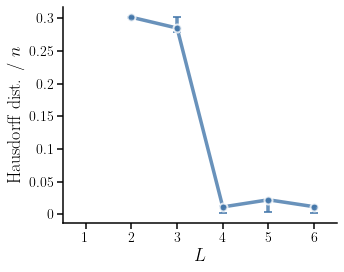

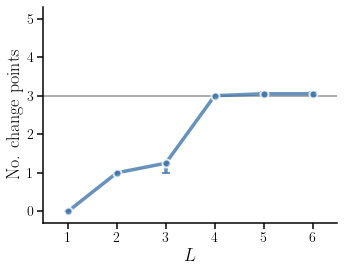

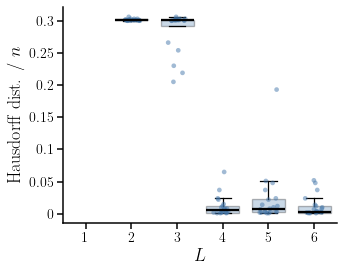

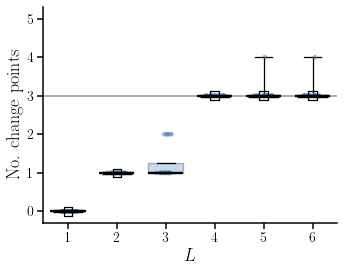

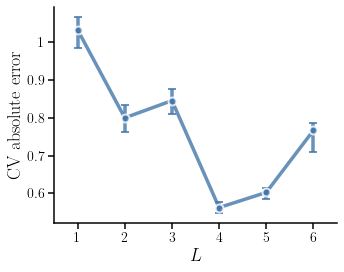

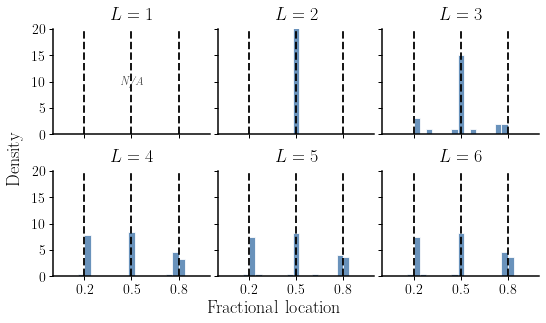

All figures use only n=1000,p=100. All bound-axis ticks are exactly 1,2,3,4,5,6.


In [1]:
# SELF-CONTAINED plotting cell. Gold-standard rcParams and box helpers copied
# verbatim from M3_upsample_final.ipynb; only labels/data dimensions differ.
import pickle, json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, FixedLocator, FixedFormatter
plt.switch_backend('module://matplotlib_inline.backend_inline')
plt.rcParams.update({'pgf.texsystem': 'pdflatex', 'pgf.preamble': '\n        \\usepackage{amsmath}\n        \\usepackage{amsfonts}\n        \\usepackage{amssymb}\n        \\usepackage{siunitx}\n    ', 'font.size': 14, 'font.family': 'serif', 'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'], 'text.usetex': True, 'axes.linewidth': 1.5, 'axes.labelsize': 18, 'axes.titlesize': 18, 'xtick.labelsize': 14, 'ytick.labelsize': 14, 'legend.fontsize': 14, 'legend.frameon': True, 'legend.fancybox': True, 'legend.edgecolor': 'black', 'legend.framealpha': 0.95, 'lines.linewidth': 4.0, 'lines.markersize': 8, 'figure.dpi': 72, 'savefig.dpi': 300, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.1})
_COLLAPSED_STYLES = {"line", "line_and_marker", "none"}
def get_asymmetric_errors(data):
    """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
    means = np.nanmean(data, axis=1)
    p25 = np.nanpercentile(data, 25, axis=1)
    p75 = np.nanpercentile(data, 75, axis=1)
    lower_errors = np.abs(means - p25)
    upper_errors = np.abs(p75 - means)
    return [lower_errors, upper_errors]

def _finite_1d(values):
    """Return a flattened float array containing only finite observations."""
    values = np.asarray(values, dtype=float).ravel()
    return values[np.isfinite(values)]

def _distribution_summary(values):
    """Compute the summaries used by all distribution-plotting modes."""
    values = _finite_1d(values)
    if values.size == 0:
        return None

    q05, q25, median, q75, q95 = np.percentile(
        values, [5, 25, 50, 75, 95]
    )
    data_scale = max(
        1.0,
        float(np.max(np.abs(values))),
        float(np.ptp(values)),
    )
    collapsed = np.isclose(
        q25,
        q75,
        rtol=1e-10,
        atol=1e-12 * data_scale,
    )

    return {
        "n": int(values.size),
        "n_unique": int(np.unique(values).size),
        "min": float(np.min(values)),
        "q05": float(q05),
        "q25": float(q25),
        "median": float(median),
        "q75": float(q75),
        "q95": float(q95),
        "max": float(np.max(values)),
        "iqr": float(q75 - q25),
        "collapsed": bool(collapsed),
    }

def _jittered_x(position, n, rng, jitter_width):
    """Generate reproducible horizontal jitter without changing y values."""
    if n <= 1 or jitter_width <= 0:
        return np.full(n, position, dtype=float)
    return position + rng.uniform(-jitter_width, jitter_width, size=n)

def _draw_raw_points(
    ax,
    values,
    position,
    color,
    rng,
    jitter_width=0.18,
    point_size=22,
    point_alpha=0.16,
):
    """Overlay all observations using x-only jitter."""
    x = _jittered_x(position, values.size, rng, jitter_width)
    ax.scatter(
        x,
        values,
        s=point_size,
        facecolor=color,
        edgecolor="none",
        alpha=point_alpha,
        zorder=4,
        clip_on=True,
        label="_nolegend_",
    )

def _draw_collapsed_iqr(
    ax,
    position,
    median,
    box_width,
    collapsed_style="line_and_marker",
):
    """
    Make a zero-IQR group visible without inventing a nonzero statistical box.

    The optional square is a display glyph only; it does not encode an interval.
    """
    if collapsed_style not in _COLLAPSED_STYLES:
        raise ValueError(
            f"collapsed_style must be one of {sorted(_COLLAPSED_STYLES)}, "
            f"got {collapsed_style!r}."
        )
    if collapsed_style == "none":
        return

    half_width = 0.43 * box_width
    ax.plot(
        [position - half_width, position + half_width],
        [median, median],
        color="black",
        linewidth=3.4,
        solid_capstyle="butt",
        zorder=7,
        label="_nolegend_",
    )

    if collapsed_style == "line_and_marker":
        ax.scatter(
            [position],
            [median],
            marker="s",
            s=72,
            facecolor="none",
            edgecolor="black",
            linewidth=1.25,
            zorder=8,
            label="_nolegend_",
        )

def _draw_box_jitter_group(
    ax,
    values,
    position,
    color,
    rng,
    summary,
    box_width,
    jitter_width,
    point_size,
    point_alpha,
    collapsed_style,
):
    """Draw one honest boxplot and overlay all observations."""
    bp = ax.boxplot(
        [values],
        positions=[position],
        widths=box_width,
        patch_artist=True,
        showfliers=False,       # every observation is shown by the scatter layer
        whis=1.5,
        autorange=True,         # if IQR=0, extend whiskers to min/max
        manage_ticks=False,
        medianprops={
            "color": "black",
            "linewidth": 2.3,
            "zorder": 6,
        },
        boxprops={
            "color": "black",
            "linewidth": 1.35,
            "zorder": 2,
        },
        whiskerprops={
            "color": "black",
            "linewidth": 1.25,
            "zorder": 2,
        },
        capprops={
            "color": "black",
            "linewidth": 1.25,
            "zorder": 2,
        },
    )

    patch = bp["boxes"][0]
    patch.set_facecolor(color)
    patch.set_alpha(0.28)
    patch.set_edgecolor("black")

    _draw_raw_points(
        ax=ax,
        values=values,
        position=position,
        color=color,
        rng=rng,
        jitter_width=jitter_width,
        point_size=point_size,
        point_alpha=point_alpha,
    )

    # Reinforce the statistical line when the box height is genuinely zero.
    if summary["collapsed"]:
        _draw_collapsed_iqr(
            ax=ax,
            position=position,
            median=summary["median"],
            box_width=box_width,
            collapsed_style=collapsed_style,
        )
# Plot ONLY the selected n=1000, p=100 experiment.
with Path('results/E_L_upper_bound_n1000_p100/study.pkl').open('rb') as handle:
    study = pickle.load(handle)
assert study['settings'] == [(1000, 100)]
rows = study['rows'][(1000, 100)]
assert len(rows) == 20 and all(r['n'] == 1000 and r['p'] == 100 for r in rows)
L_values = np.arange(1, 7)
blue = '#4477AA'
truth = np.array([.2, .5, .8])
figures_dir = Path('figures'); figures_dir.mkdir(exist_ok=True)
plot_audit = []
fmt = FuncFormatter(lambda value, pos: f'{value:.3f}'.rstrip('0').rstrip('.') if abs(value) > 1e-12 else '0')

def finish_axes(ax, ylabel):
    ax.set_xlabel(r'$L$', fontsize=18)
    ax.set_ylabel(ylabel, fontsize=18)
    # Fixed positions AND fixed labels, after drawing boxes: no Matplotlib-managed duplicates.
    ax.xaxis.set_major_locator(FixedLocator(L_values))
    ax.xaxis.set_major_formatter(FixedFormatter([str(L) for L in L_values]))
    ax.set_xlim(.5, 6.5)
    ax.yaxis.set_major_formatter(fmt)
    ax.tick_params(axis='both', which='major', width=1.5, length=6, labelsize=14)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5); ax.spines['bottom'].set_linewidth(1.5)
    np.testing.assert_array_equal(ax.get_xticks(), L_values)
    assert [t.get_text() for t in ax.get_xticklabels()] == ['1','2','3','4','5','6']

def save_figure(fig, suffix):
    for extension in ['pdf','png','pgf']:
        fig.savefig(figures_dir / f'E_L_upper_bound_n1000_p100_{suffix}.{extension}', dpi=600 if extension == 'png' else None)
    fig.canvas.draw()
    plot_audit.append(dict(name=suffix,settings=dict(n=1000,p=100),figsize=list(fig.get_size_inches()),axes=[dict(
        xlabel=ax.get_xlabel(),ylabel=ax.get_ylabel(),title=ax.get_title(),
        xticks=ax.get_xticks().tolist(),xticklabels=[t.get_text() for t in ax.get_xticklabels()],
        xlabel_size=ax.xaxis.label.get_fontsize(),ylabel_size=ax.yaxis.label.get_fontsize(),
        ylim=list(ax.get_ylim())) for ax in fig.axes]))
    plt.show()

print('n=1000, p=100; Delta_n=n/20; 20 paired trials; 10-fold absolute-error CV.')
print('L | selected number of signals | correct-count frequency | empty frequency | Hausdorff dist. / n')
for L in L_values:
    fits=[r['fits'][int(L)] for r in rows]
    finite=[f['haus'] for f in fits if np.isfinite(f['haus'])]
    h=f'{np.mean(finite):.3f}' if finite else 'undefined'
    print(f'{L} | {np.mean([f["selected"] for f in fits]):.3f} | '
          f'{np.mean([f["correct_count"] for f in fits]):.3f} | '
          f'{np.mean([f["empty"] for f in fits]):.3f} | {h}')

# Same error-bar calculation and drawing syntax as the canonical gold plots.
for metric, ylabel, suffix in [('haus',r'Hausdorff dist. / $n$','location_asymmetric_errors'),
                              ('change_points','No. change points','change_points_asymmetric_errors')]:
    values=np.array([[(r['fits'][int(L)]['selected']-1 if metric=='change_points' else r['fits'][int(L)][metric]) for r in rows] for L in L_values],float)
    keep=np.isfinite(values).any(axis=1)
    fig,ax=plt.subplots(1,1,figsize=(5.0,4.0))
    means=np.nanmean(values[keep],axis=1)
    errors=get_asymmetric_errors(values[keep])
    ax.errorbar(L_values[keep],means,yerr=errors,marker='o',ls='-',color=blue,
                capsize=4,capthick=2,markersize=8,linewidth=3.5,
                markeredgewidth=2,markeredgecolor='white',alpha=.8)
    finish_axes(ax,ylabel)
    if metric=='change_points':
        ax.set_yticks([0,1,2,3,4,5]);ax.set_ylim(-.3,5.3)
        ax.axhline(3,color='gray',linewidth=1.5,alpha=.85,zorder=0)
    fig.tight_layout();save_figure(fig,suffix)

# Literally copied gold-standard box/jitter renderer (manage_ticks=False).
for metric,ylabel,suffix in [('haus',r'Hausdorff dist. / $n$','location_boxplots'),
                            ('change_points','No. change points','change_points_boxplots')]:
    fig,ax=plt.subplots(1,1,figsize=(5.0,4.0))
    rng=np.random.default_rng(2026)
    for L in L_values:
        values=_finite_1d([r['fits'][int(L)]['selected']-1 if metric=='change_points' else r['fits'][int(L)][metric] for r in rows])
        summary=_distribution_summary(values)
        if summary is None:continue
        _draw_box_jitter_group(ax=ax,values=values,position=float(L),color=blue,rng=rng,
            summary=summary,box_width=.72,jitter_width=.20,point_size=22,
            point_alpha=.50,collapsed_style='line_and_marker')
    finish_axes(ax,ylabel)
    if metric=='change_points':
        ax.set_yticks([0,1,2,3,4,5]);ax.set_ylim(-.3,5.3)
        ax.axhline(3,color='gray',linewidth=1.5,alpha=.85,zorder=0)
    fig.tight_layout();save_figure(fig,suffix)

# Retained score diagnostic, restricted to the same selected setting.
scores=np.array([r['fits'][6]['scores'] for r in rows])/1000
fig,ax=plt.subplots(1,1,figsize=(5.0,4.0))
ax.errorbar(L_values,scores.mean(axis=0),yerr=get_asymmetric_errors(scores.T),
    marker='o',ls='-',color=blue,capsize=4,capthick=2,markersize=8,
    linewidth=3.5,markeredgewidth=2,markeredgecolor='white',alpha=.8)
finish_axes(ax,'CV absolute error')
fig.tight_layout();save_figure(fig,'cv_scores')

# Larger, spaced histogram panels:25 bins, white edges, black dashed truths; no KDE.
fig,axes=plt.subplots(2,3,figsize=(2.5*3,2.2*2),sharex=True,sharey=True,
    gridspec_kw={'wspace':.05,'hspace':.35})
fig.patch.set_facecolor('white')
for ax,L in zip(axes.flat,L_values):
    pooled=np.concatenate([np.asarray(r['fits'][int(L)]['cp'])/1000 for r in rows])
    ax.set_facecolor('white')
    if len(pooled):
        ax.hist(pooled,bins=np.linspace(0,1,26),alpha=.8,color=blue,
            density=True,edgecolor='white',linewidth=1.0)
    else:
        ax.text(.5,.5,r'\textit{N/A}',transform=ax.transAxes,ha='center',va='center',fontsize=12,alpha=.7,style='italic')
    for boundary in truth:ax.axvline(boundary,color='black',linestyle='--',linewidth=2,alpha=.9,zorder=10)
    ax.set_title(rf'$L={L}$',fontsize=18,pad=10)
    ax.set_xlim(0,1)
    ax.set_xticks(truth);ax.set_xticklabels([r'$0.2$',r'$0.5$',r'$0.8$'],fontsize=14)
    ax.yaxis.set_major_formatter(fmt)
    ax.tick_params(axis='both',which='major',width=1,length=4,labelsize=14)
    ax.spines['top'].set_visible(False);ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5);ax.spines['bottom'].set_linewidth(1.5)
    assert ax.get_title()==rf'$L={L}$' and 'empty' not in ax.get_title()
# Requested common density range; histogram-only display.
axes[0,0].set_ylim(0,20)
axes[0,0].set_yticks([0,5,10,15,20])
fig.text(.5,.005,'Fractional location',ha='center',va='bottom',fontsize=18)
fig.text(.005,.5,'Density',va='center',rotation='vertical',fontsize=18)
fig.subplots_adjust(left=.09,right=.99,bottom=.13,top=.91)
save_figure(fig,'changepoint_histograms')
with Path('results/E_L_upper_bound_n1000_p100/plot_audit.json').open('w') as handle:
    json.dump(plot_audit,handle,indent=2)
print('All figures use only n=1000,p=100. All bound-axis ticks are exactly 1,2,3,4,5,6.')
